# Computer Vision

Let's do some very basic computer vision. We're going to import the MNIST handwritten digits data and $k$NN to predict values (i.e. "see/read").

1. To load the data, run the following code in a chunk:
```
import pickle
with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']
```
The `y_test` and `y_train` vectors, for each index `i`, tell you want number is written in the corresponding index in `X_train[i]` and `X_test[i]`. The value of `X_train[i]` and `X_test[i]`, however, is a 28$\times$28 array whose entries contain values between 0 and 256. Each element of the matrix is essentially a "pixel" and the matrix encodes a representation of a number. To visualize this, run the following code to see the first ten numbers:
```
import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5): 
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()
```
OK, those are the data: Labels attached to handwritten digits encoded as a matrix.

2. What is the shape of `X_train` and `X_test`? What is the shape of `X_train[i]` and `X_test[i]` for each index `i`? What is the shape of `y_train` and `y_test`?
3. Use Numpy's `.reshape()` method to covert the training and testing data from a matrix into an vector of features. So, `X_test[index].reshape((1,784))` will convert the $index$-th element of `X_test` into a $28\times 28=784$-length row vector of values, rather than a matrix. Turn `X_train` into an $N \times 784$ matrix $X$ that is suitable for scikit-learn's kNN classifier where $N$ is the number of observations and $784=28*28$ (you could use, for example, a `for` loop).
4. Use the reshaped `X_test` and `y_test` data to create a $k$-nearest neighbor classifier of digit. What is the optimal number of neighbors $k$? If you can't determine this, play around with different values of $k$ for your classifier.
5. For the optimal number of neighbors, how well does your predictor perform on the test set? Report the accuracy, compute a confusion matrix, and explain your findings.
6. For your confusion matrix, which mistakes are most likely? Do you find any interesting patterns?
7. So, this is how computers "see." They convert an image into a matrix of values, that matrix becomes a vector in a dataset, and then we deploy ML tools on it as if it was any other kind of tabular data. To make sure you follow this, invent a way to represent a color photo in matrix form, and then describe how you could convert it into tabular data. (Hint: RGB color codes provide a method of encoding a numeric value that represents a color.)

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Leyton Allen, Cody Chhea, Ayesha Habib, Roshan Mahesh

**Date:** 11/4/2026

Q1.

Digit: 7


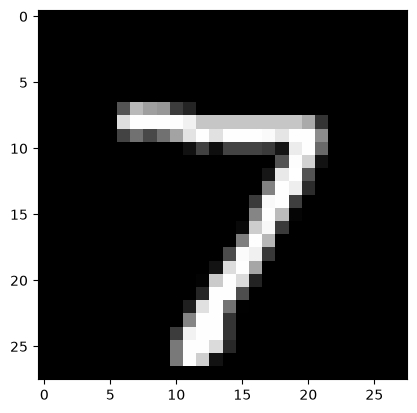

Digit: 2


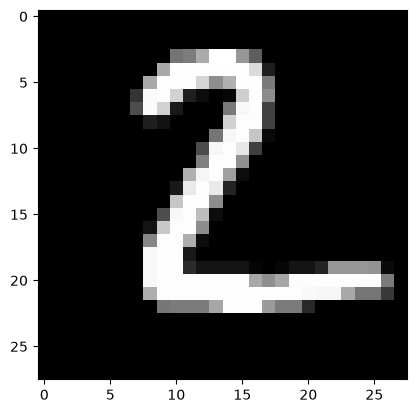

Digit: 1


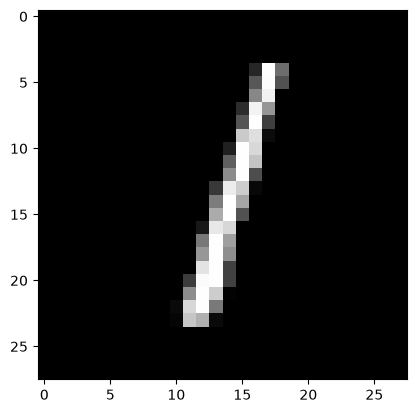

Digit: 0


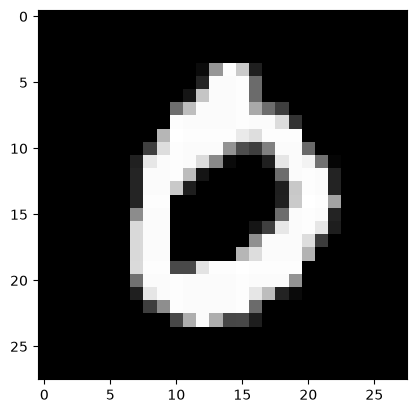

Digit: 4


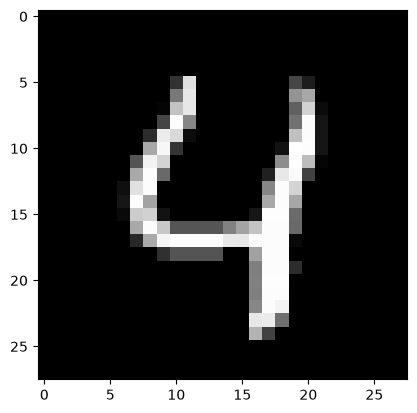

In [28]:
import pickle
import matplotlib.pyplot as plt
import numpy as np

with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)

X_train = data['X_train']
y_train = data['y_train']
X_test = data['X_test']
y_test = data['y_test']

for i in range(5):
    print("Digit:", y_test[i])
    plt.imshow(X_test[i], cmap='gray')
    plt.show()

Q2.

In [29]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("One training image:", X_train[0].shape)
print("One testing image:", X_test[0].shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (60000, 28, 28)
X_test: (10000, 28, 28)
One training image: (28, 28)
One testing image: (28, 28)
y_train: (60000,)
y_test: (10000,)


Q2.

X_train and X_test contain the images, while y_train and y_test contain the digit labels. Each image is 28 by 28 pixels, which means it contains 784 pixels total.

Q3.

In [30]:
X_train_new = X_train.reshape(len(X_train), 784)
X_test_new = X_test.reshape(len(X_test), 784)

print("Training data:", X_train_new.shape)
print("Testing data:", X_test_new.shape)

Training data: (60000, 784)
Testing data: (10000, 784)


Q3.

I reshaped the training and testing images into rows of 784 values because each image contains 28 × 28 pixels. This allows the data to be used by the kNN classifier.

Q4.

In [31]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

for k in [3, 5, 7]:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_new, y_train)

    predictions = model.predict(X_test_new)
    accuracy = accuracy_score(y_test, predictions)

    print("k =", k, "Accuracy =", accuracy)

k = 3 Accuracy = 0.9705
k = 5 Accuracy = 0.9688
k = 7 Accuracy = 0.9694


In [32]:
k = 3

model = KNeighborsClassifier(n_neighbors=k)
model.fit(X_train_new, y_train)

predictions = model.predict(X_test_new)

Q4.

I tested k values of 3, 5, and 7 to see which worked best. I chose k = 3 because it had the highest accuracy of 97.05%.

Q5.

In [33]:
from sklearn.metrics import confusion_matrix

accuracy = accuracy_score(y_test, predictions)
cm = confusion_matrix(y_test, predictions)

print("Accuracy:", accuracy)
print("Confusion Matrix:")
print(cm)

Accuracy: 0.9705
Confusion Matrix:
[[ 974    1    1    0    0    1    2    1    0    0]
 [   0 1133    2    0    0    0    0    0    0    0]
 [  10    9  996    2    0    0    0   13    2    0]
 [   0    2    4  976    1   13    1    7    3    3]
 [   1    6    0    0  950    0    4    2    0   19]
 [   6    1    0   11    2  859    5    1    3    4]
 [   5    3    0    0    3    3  944    0    0    0]
 [   0   21    5    0    1    0    0  991    0   10]
 [   8    2    4   16    8   11    3    4  914    4]
 [   4    5    2    8    9    2    1    8    2  968]]


Q5.

The classifier had an accuracy of 97.05%, meaning it correctly predicted most of the handwritten digits. The confusion matrix shows which digits were predicted correctly and which digits the model confused with others.

Q6.

In [34]:
mistakes = cm.copy()
np.fill_diagonal(mistakes, 0)

for i in range(3):
    row, col = np.unravel_index(np.argmax(mistakes), mistakes.shape)

    print("Actual:", row, "Predicted:", col)
    print("Number of mistakes:", mistakes[row, col])

    mistakes[row, col] = 0

Actual: 7 Predicted: 1
Number of mistakes: 21
Actual: 4 Predicted: 9
Number of mistakes: 19
Actual: 8 Predicted: 3
Number of mistakes: 16


Q6.

The most common mistake was predicting a 7 as a 1, which happened 21 times. Another common mistake was predicting a 4 as a 9, which happened 19 times. The model also predicted an 8 as a 3 a total of 16 times.

I think these mistakes happen because some handwritten digits look similar. For example, a 7 might look like a 1 depending on how someone writes it. Overall, the classifier performed well, but certain digits were harder to distinguish.

Q7.

A color photo can be represented using three matrices for red, green, and blue (RGB). Each pixel has three values that represent how much of each color it contains.

For example, a 100 by 100 image would have a shape of (100, 100, 3). To turn this into tabular data, I would reshape the image into one row with 30,000 values. Each image would be a separate row in the dataset. This would allow a machine learning model to analyze the images.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 0dd1f5a123a70b94c51b062480a6080239a0398d
- **AI tool and model used:** ChatGPT (GPT-6)

### *Prompts used

1. Can you improve my code for loading and displaying the images?
2. Can you improve how I check the shapes of the data?
3. Can you make my code for reshaping the images better?
4. Can you improve my kNN classifier and help find the best k value?
5. Can you improve my accuracy results and confusion matrix?
6. Can you help me better understand which digits the model gets wrong?
7. Can you improve my explanation of how computers see color images?

### *AI-proposed changes


1. Display more images together to make them easier to compare.
2. Add checks to make sure the data has the correct shapes.
3. Improve the reshaping code and check that each image has 784 values.
4. Test more k values and use validation data to find the best one.
5. Add a clearer confusion matrix and more accuracy measures.
6. Show examples of incorrectly predicted digits.
7. Improve the explanation of how color images are represented.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Makes the images easier to compare. Check that all 10 images display correctly. |
| 2 | Accept | Helps catch mistakes in the data. Check that the shape tests pass. |
| 3 | Accept | Makes reshaping more flexible. Verify that each image has 784 values. |
| 4 | Accept | Helps choose k without relying on test accuracy. Compare the validation results. |
| 5 | Accept | Makes the results easier to understand. Check the accuracy and confusion matrix. |
| 6 | Accept | Helps explain mistakes. Compare actual and predicted digits. |
| 7 | Accept | Gives a more complete explanation of color images. Check the RGB dimensions and calculations. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

Q1.

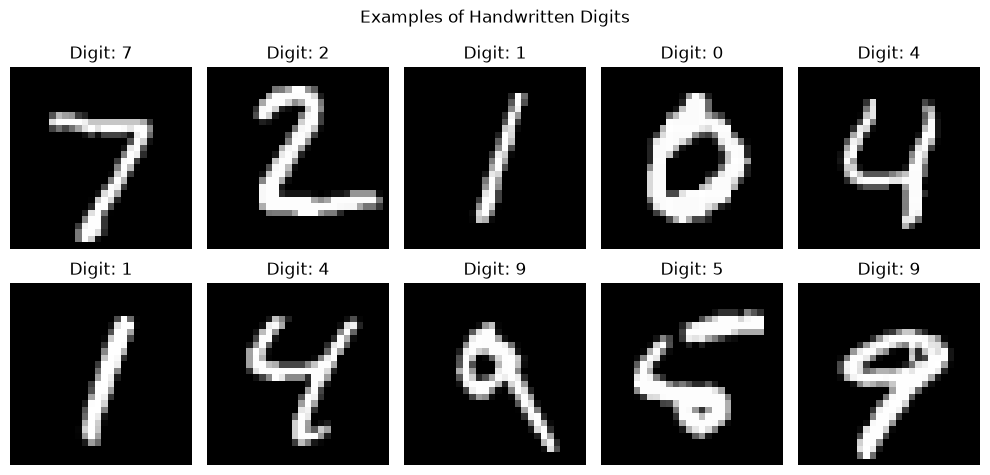

In [35]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)

X_train = data['X_train']
y_train = data['y_train']
X_test = data['X_test']
y_test = data['y_test']

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(X_test[i], cmap='gray')
    ax.set_title("Digit: " + str(y_test[i]))
    ax.axis('off')

plt.suptitle("Examples of Handwritten Digits")
plt.tight_layout()
plt.show()


Q1.

In Phase 1, I displayed five handwritten digits separately. In Phase 2, I displayed ten digits together in a grid. This makes it easier to compare the different images and keeps the results more organized.

Q2.

In [36]:
print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

print("One training image:", X_train[0].shape)
print("One testing image:", X_test[0].shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

assert X_train.shape[1:] == (28, 28)
assert X_test.shape[1:] == (28, 28)

assert len(X_train) == len(y_train)
assert len(X_test) == len(y_test)

print("All shape checks passed!")

Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)
One training image: (28, 28)
One testing image: (28, 28)
Training labels: (60000,)
Testing labels: (10000,)
All shape checks passed!


Q2.

In Phase 1, I printed the shapes of the training and testing data. In Phase 2, I also added checks to make sure each image is 28 by 28 pixels and that the number of images matches the number of labels. This helps catch errors in the dataset.

Q3.

In [37]:
X_train_flat = X_train.reshape(len(X_train), -1)
X_test_flat = X_test.reshape(len(X_test), -1)

print("Training data:", X_train_flat.shape)
print("Testing data:", X_test_flat.shape)

assert X_train_flat.shape[1] == 784
assert X_test_flat.shape[1] == 784

print("Reshaping was successful!")

Training data: (60000, 784)
Testing data: (10000, 784)
Reshaping was successful!


Q3.

In Phase 1, I reshaped the images using 784 as the number of features. In Phase 2, I used -1 so Python automatically calculates the number of features. I also added checks to make sure each image has 784 values. This makes the code more flexible and helps catch errors.

Q4.

k = 1 Validation Accuracy = 0.9704
k = 3 Validation Accuracy = 0.9703
k = 5 Validation Accuracy = 0.9675
k = 7 Validation Accuracy = 0.9663
k = 9 Validation Accuracy = 0.9654
Best k: 1


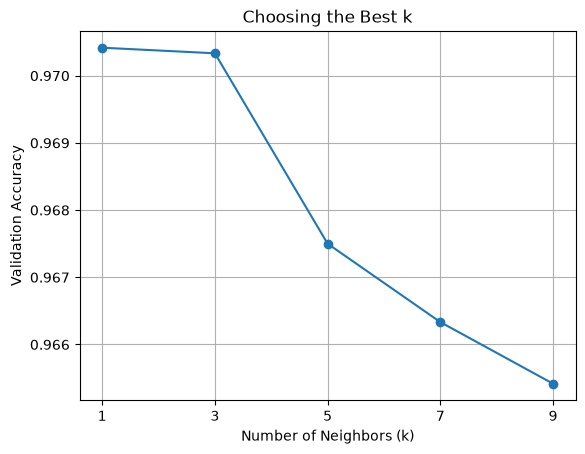

In [38]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import numpy as np
import matplotlib.pyplot as plt

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_flat,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

k_values = [1, 3, 5, 7, 9]
scores = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_fit, y_fit)

    val_predictions = model.predict(X_val)
    score = accuracy_score(y_val, val_predictions)

    scores.append(score)
    print("k =", k, "Validation Accuracy =", round(score, 4))

best_k = k_values[np.argmax(scores)]
print("Best k:", best_k)

plt.plot(k_values, scores, marker='o')
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Validation Accuracy")
plt.title("Choosing the Best k")
plt.xticks(k_values)
plt.grid(True)
plt.show()

Q4.

In Phase 1, I tested three values of k using the test data. In Phase 2, I tested five values and used a validation set to choose the best one. I also created a graph to compare their accuracy. This is better because I can choose k without using the final test results.

Q5.

Best k: 1
Test Accuracy: 0.9691

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       980
           1       0.97      0.99      0.98      1135
           2       0.98      0.96      0.97      1032
           3       0.96      0.96      0.96      1010
           4       0.97      0.96      0.97       982
           5       0.95      0.96      0.96       892
           6       0.98      0.99      0.98       958
           7       0.96      0.96      0.96      1028
           8       0.98      0.94      0.96       974
           9       0.96      0.96      0.96      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



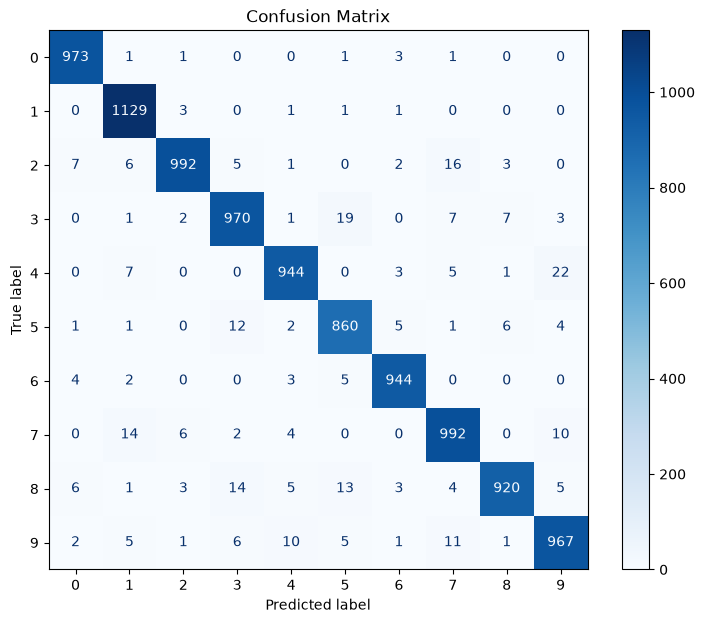

In [39]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

final_model = KNeighborsClassifier(n_neighbors=best_k)
final_model.fit(X_train_flat, y_train)

final_predictions = final_model.predict(X_test_flat)

accuracy = accuracy_score(y_test, final_predictions)

print("Best k:", best_k)
print("Test Accuracy:", round(accuracy, 4))

print("\nClassification Report:")
print(classification_report(y_test, final_predictions))

cm = confusion_matrix(y_test, final_predictions)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

fig, ax = plt.subplots(figsize=(9, 7))
display.plot(cmap="Blues", ax=ax)
plt.title("Confusion Matrix")
plt.show()

Q5.

In Phase 2, I used k = 1 and got an accuracy of 96.91%. This was slightly lower than my Phase 1 accuracy of 97.05%. However, Phase 2 uses validation data to choose k instead of the test data, which makes the evaluation more reliable. I also added a visual confusion matrix and a classification report to better understand the model's performance.

Q6.

In [40]:
mistakes = cm.copy()
np.fill_diagonal(mistakes, 0)

print("Most Common Mistakes:")

for i in range(5):
    row, col = np.unravel_index(np.argmax(mistakes), mistakes.shape)

    print("Actual:", row, "Predicted:", col,
          "Mistakes:", mistakes[row, col])

    mistakes[row, col] = 0

Most Common Mistakes:
Actual: 4 Predicted: 9 Mistakes: 22
Actual: 3 Predicted: 5 Mistakes: 19
Actual: 2 Predicted: 7 Mistakes: 16
Actual: 7 Predicted: 1 Mistakes: 14
Actual: 8 Predicted: 3 Mistakes: 14


Total incorrect predictions: 309


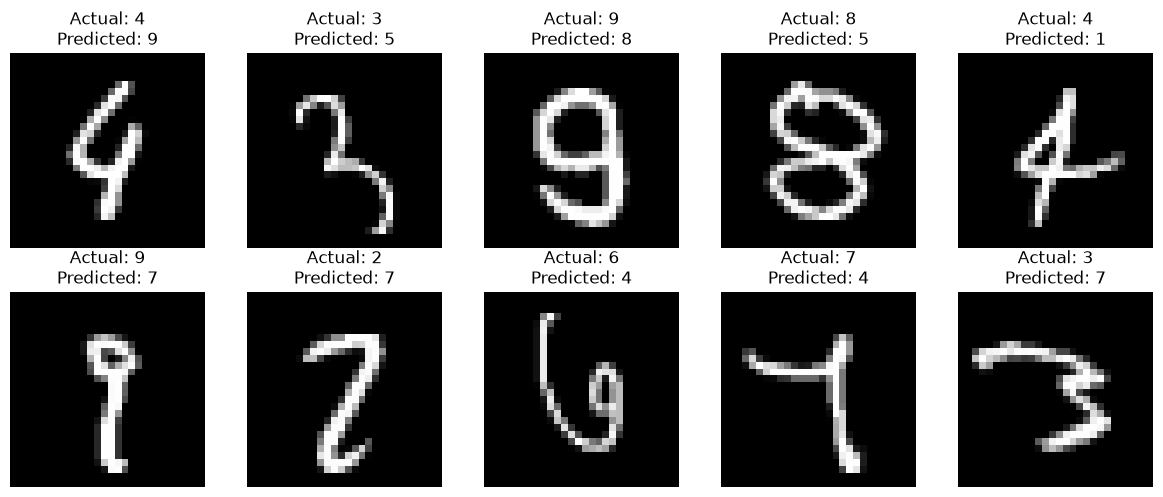

In [41]:
wrong_indices = np.where(final_predictions != y_test)[0]

print("Total incorrect predictions:", len(wrong_indices))

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for ax, index in zip(axes.flat, wrong_indices[:10]):
    ax.imshow(X_test[index], cmap="gray")
    ax.set_title(
        f"Actual: {y_test[index]}\n"
        f"Predicted: {final_predictions[index]}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

Q6.

In Phase 1, I only identified the three most common mistakes. In Phase 2, I identified the five most common mistakes and displayed images that the model predicted incorrectly. This helps me better understand why the classifier makes certain mistakes. Some handwritten digits look similar, which can cause the model to confuse them.

Q7.

In Phase 1, I explained that color images use red, green, and blue (RGB) values. In Phase 2, I expanded this explanation to include more details about how computers store and analyze color images.

A color image can be represented as a three-dimensional array containing the height, width, and three RGB color channels. Each pixel has three values, usually ranging from 0 to 255.

For example, a 100 by 100 color image has a shape of (100, 100, 3). To convert it into tabular data, the image can be reshaped into one row containing 30,000 values. If there are 500 images, the dataset would have 500 rows and 30,000 columns.

One limitation is that flattening images does not directly preserve the relationships between nearby pixels. More advanced models can recognize these patterns better.

### *Reflection on AI assistance
In your own words without generative AI.

AI helped me improve my original code in several ways. In Phase 1 my code was pretty basic and mainly focused on getting the correct results. In Phase 2 I was able to make the code more organized and add new features. Some of the main improvements included displaying more images together, adding checks for the data, and creating a better confusion matrix.

One of the biggest improvements was how I chose the best k value. In Phase 1 I got an accuracy of 97.05% using k = 3. However, in Phase 2 I used validation data to select k = 1, which gave me an accuracy of 96.91%. Even though the accuracy was slightly lower, this was a better way to evaluate the model.

AI was also not completely accurate. For example, the confusion matrix code originally had an error because the figsize argument was used incorrectly. I had to fix this before the graph would work.

I checked the AI-generated code by running each cell and looking at the results. One remaining limitation is that the model still struggles with handwritten digits that look similar. Overall, AI helped me understand the results better and improve my original solution.